# Two-branch MoE: before fixes vs final version

So sánh bản hai nhánh trước khi sửa (`memory/impala/mem_reservoir_10k`) với bản cuối (`v3/impala/final_variant_s42`), cùng thứ tự phase `variant`, seed 42, và chỉ rõ từng điểm đã sửa. Notebook chỉ đọc kết quả đã lưu (không cần GPU), chạy từ thư mục gốc dự án; hình lưu ở `figures/before_after/` (PDF và PNG), nhãn trên hình bằng tiếng Anh.

| Nhãn | Run | Ghi chú |
|---|---|---|
| **Two-branch (before fixes)** | `save/memory/impala/mem_reservoir_10k` | z-score, LayerNorm sau MoE, quy tắc `cls`, hồ sơ normal từ cả 9 bản ghi |
| **Two-branch (final)** | `save/v3/impala/final_variant_s42` | surprise + payload, null có hiệu lực, che ID lạ, quy tắc theo nhãn + kiểm tra routing, hồ sơ chỉ từ phase 1 |
| Joint upper bound | `save/v3/impala/upper_variant_s42` | cùng dữ liệu bản cuối, cùng số expert |

Ba hạn chế đã nêu tuần trước và nơi kiểm chứng:

| # | Hạn chế | Phần |
|---|---|---|
| 1 | Null expert chỉ có hiệu lực trong routing | 3 |
| 2 | Mở rộng thừa (expert gần như không được dùng) | 4 |
| 3 | Một expert trộn nhiều hành vi | 5 |

**Lưu ý:** hai bản dùng giao thức khác nhau (bản cuối chặt hơn: hồ sơ normal chỉ từ bản ghi phase 1), nên chênh lệch F1 không thuần do các bản sửa. Thí nghiệm 2 × 2 trên cùng dữ liệu v3 (phần 3) tách riêng tác dụng của các bản sửa kiến trúc.

In [16]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path(".")
SAVE = ROOT / "../save"
FIG = ROOT / "figures/before_after"
FIG.mkdir(parents=True, exist_ok=True)

OLD = "Two-branch (before fixes)"
NEW = "Two-branch (after)"
RUN_DIRS = {OLD: SAVE / "memory/impala/mem_reservoir_10k",
            NEW: SAVE / "v3/impala/final_variant_s42"}
UPPER_DIR = SAVE / "v3/impala/upper_variant_s42"
COLOR = {OLD: "#4C72B0", NEW: "#D62728"}
SHORT = {OLD: "Before fixes", NEW: "Final"}

CLASS_NAMES = ["normal", "dos", "fuzzing", "gear", "interval", "rpm", "speed",
               "standstill", "systematic", "combined"]
PHASES = ["phase1", "phase2", "phase3", "phase4", "phase5"]
PHASE_LABEL = ["P1\nbase", "P2\n+speed", "P3\nDoS variant", "P4\n+standstill", "P5\n+systematic\n+combined"]

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "savefig.bbox": "tight"})

def savefig(name):
    plt.savefig(FIG / f"{name}.pdf"); plt.savefig(FIG / f"{name}.png", dpi=200)

def load_run(d):
    d = Path(d)
    if not (d / "results.json").exists():
        return None
    r = {"dir": d, "results": json.load(open(d / "results.json"))}
    r["cl"] = json.load(open(d / "cl_summary.json")) if (d / "cl_summary.json").exists() else {}
    r["by_phase"] = {x["phase"]: x for x in r["results"]}
    return r

def load_preds(d, phase="phase5"):
    p = Path(d) / f"preds_{phase}.npz"
    return dict(np.load(p)) if p.exists() else None

def has_nodes(p):
    return p is not None and "node_probs" in p

RUNS = {lab: load_run(d) for lab, d in RUN_DIRS.items()}
UPPER = load_run(UPPER_DIR)
P = {lab: load_preds(d) for lab, d in RUN_DIRS.items()}
for lab, d in RUN_DIRS.items():
    print(f"{lab:<26} {'found' if RUNS[lab] else 'MISSING'}  {d}")
print(f"{'Joint upper bound':<26} {'found' if UPPER else 'missing'}  {UPPER_DIR}")

Two-branch (before fixes)  found  ../save/memory/impala/mem_reservoir_10k
Two-branch (after)         found  ../save/v3/impala/final_variant_s42
Joint upper bound          found  ../save/v3/impala/upper_variant_s42


## 0. Kiểm tra tập test

In [17]:
check = pd.DataFrame({lab: np.bincount(p["y"], minlength=len(CLASS_NAMES))
                      for lab, p in P.items() if p is not None}, index=CLASS_NAMES).T
check["total"] = check.sum(1)
display(check)
print("Same test windows per class." if (check.nunique() == 1).all() else
      "WARNING: test sets differ (compare relative numbers only).")

,normal,dos,fuzzing,gear,interval,rpm,speed,standstill,systematic,combined,total
Two-branch (before fixes),18000,1112,1925,657,1089,947,1414,505,909,1875,28433
Two-branch (after),18000,1112,1925,657,1089,947,1414,505,909,1875,28433


Same test windows per class.


## 1. Kết quả tổng hợp (phase 5)

,Macro F1,Normal FPR,Detection rate,Forgetting (mean),Forgetting (max),Experts,"NMI(expert, class)"
Model,,,,,,,
Two-branch (before fixes),0.9861,0.0064,0.9848,0.0051,0.0154,7,0.4319
Two-branch (after),0.9892,0.0033,0.9847,0.0040,0.0107,5,0.5302
Joint upper bound,0.9952,0.0028,0.9931,0.0011,0.0030,5,0.3868


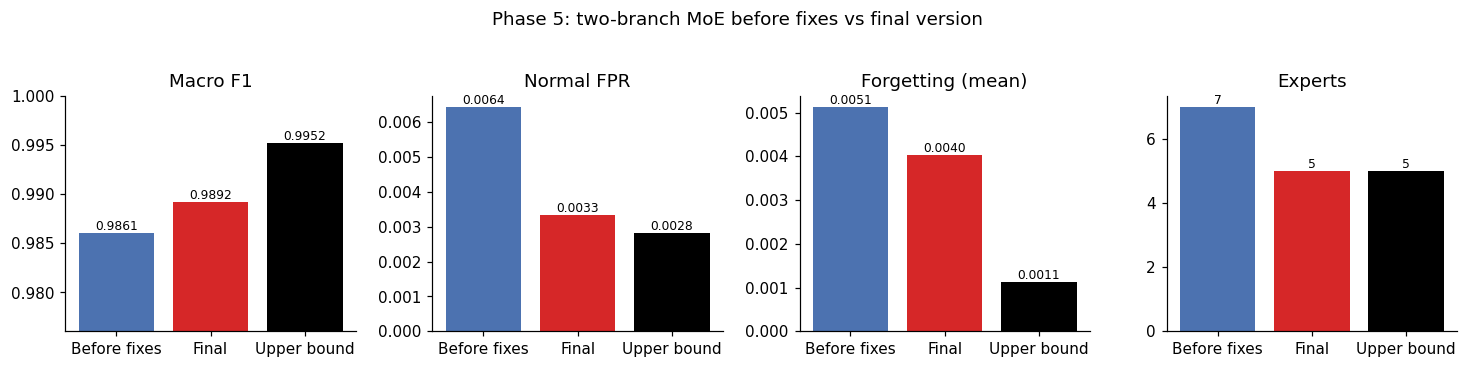

In [18]:
def summary_row(lab, r):
    last = r["results"][-1]
    sp = last.get("specialization") or {}
    return {"Model": lab, "Macro F1": last["overall"]["macro_f1"],
            "Normal FPR": last["overall"]["normal_fpr"],
            "Detection rate": last["overall"]["detection_rate"],
            "Forgetting (mean)": r["cl"].get("forgetting_mean"),
            "Forgetting (max)": r["cl"].get("forgetting_max"),
            "Experts": last.get("num_experts"),
            "NMI(expert, class)": sp.get("nmi_active_class")}

rows = [summary_row(lab, r) for lab, r in RUNS.items() if r]
if UPPER:
    rows.append(summary_row("Joint upper bound", UPPER))
summary = pd.DataFrame(rows).set_index("Model")
display(summary.round(4))

metrics = ["Macro F1", "Normal FPR", "Forgetting (mean)", "Experts"]
fig, axes = plt.subplots(1, 4, figsize=(13.5, 3.2))
for ax, m in zip(axes, metrics):
    v = summary[m].dropna()
    bars = ax.bar([SHORT.get(l, "Upper bound") for l in v.index], v.values,
                  color=[COLOR.get(l, "black") for l in v.index])
    for b, val in zip(bars, v.values):
        ax.text(b.get_x() + b.get_width() / 2, val, f"{val:.4f}" if val < 1.5 else f"{int(val)}",
                ha="center", va="bottom", fontsize=8)
    ax.set_title(m)
    if m == "Macro F1":
        ax.set_ylim(max(0.95, v.min() - 0.01), 1.0)
fig.suptitle("Phase 5: two-branch MoE before fixes vs final version", y=1.03)
fig.tight_layout(); savefig("fig1_summary"); plt.show()

## 2. Quỹ đạo theo phase và F1 từng lớp

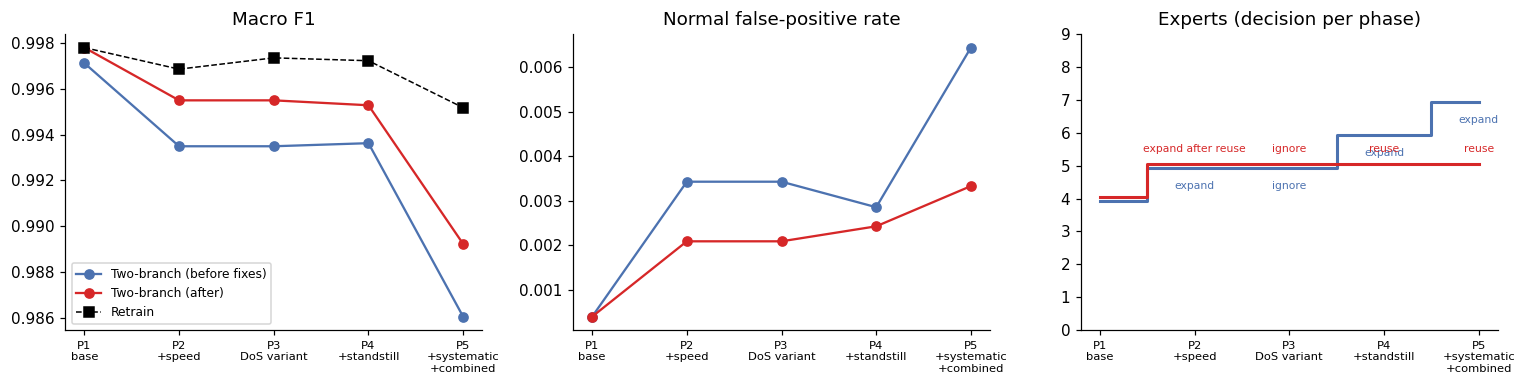

,Two-branch (before fixes),Two-branch (after),Δ (final − before)
normal,0.9924,0.9939,0.0015
dos,0.9986,0.9991,0.0005
fuzzing,0.9909,0.9930,0.0021
gear,0.9839,0.9877,0.0039
interval,0.9940,0.9936,-0.0005
rpm,0.9910,0.9904,-0.0006
speed,0.9806,0.9862,0.0057
standstill,0.9910,0.9970,0.0060
systematic,0.9857,0.9880,0.0023
combined,0.9525,0.9634,0.0109


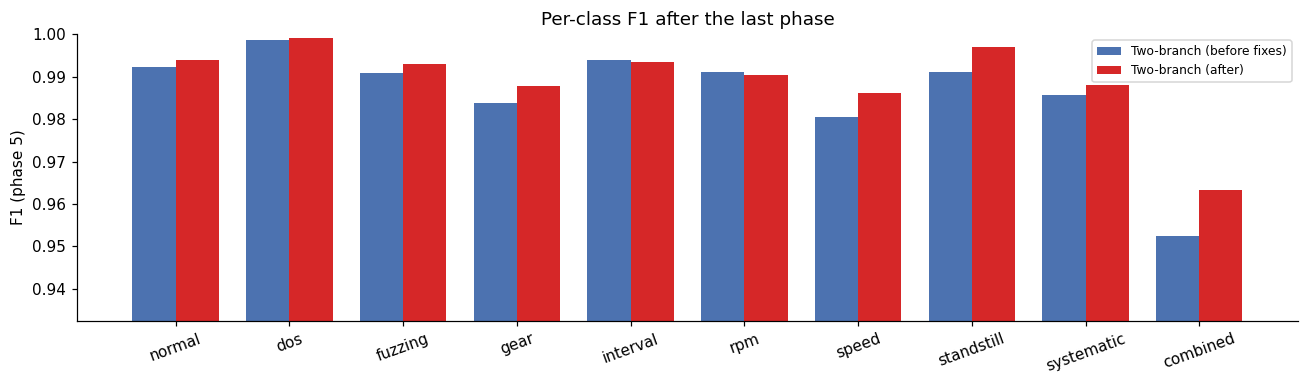

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for lab, r in RUNS.items():
    if not r:
        continue
    f1 = [r["by_phase"][p]["overall"]["macro_f1"] for p in PHASES]
    fpr = [r["by_phase"][p]["overall"]["normal_fpr"] for p in PHASES]
    ne = np.array([r["by_phase"][p].get("num_experts", np.nan) for p in PHASES], float)
    axes[0].plot(range(5), f1, "o-", color=COLOR[lab], label=lab)
    axes[1].plot(range(5), fpr, "o-", color=COLOR[lab], label=lab)
    off = 0.06 if lab == NEW else -0.06
    axes[2].step(range(5), ne + off, where="mid", color=COLOR[lab], lw=2, label=lab)
    for i, p in enumerate(PHASES[1:], start=1):
        d = r["by_phase"][p].get("decision_info", {}).get("decision", "")
        axes[2].annotate(d.replace("_", " "), (i, ne[i]), textcoords="offset points",
                         xytext=(0, 9 if lab == NEW else -15), ha="center", fontsize=7, color=COLOR[lab])
if UPPER:
    axes[0].plot(range(5), [UPPER["by_phase"][p]["overall"]["macro_f1"] for p in PHASES],
                 "s--", color="black", lw=1, label="Retrain")
for ax, t in zip(axes, ("Macro F1", "Normal false-positive rate", "Experts (decision per phase)")):
    ax.set_xticks(range(5)); ax.set_xticklabels(PHASE_LABEL, fontsize=7.5); ax.set_title(t)
axes[2].set_ylim(0, 9); axes[0].legend(fontsize=8)
fig.tight_layout(); savefig("fig2_trajectory"); plt.show()

pc = pd.DataFrame({lab: [r["results"][-1]["per_attack"].get(c, np.nan) for c in CLASS_NAMES]
                   for lab, r in RUNS.items() if r}, index=CLASS_NAMES)
if OLD in pc and NEW in pc:
    pc["Δ (final − before)"] = pc[NEW] - pc[OLD]
display(pc.round(4))
fig, ax = plt.subplots(figsize=(12, 3.6))
x = np.arange(len(CLASS_NAMES)); w = 0.38
for i, lab in enumerate([l for l in (OLD, NEW) if l in pc]):
    ax.bar(x + (i - 0.5) * w, pc[lab], w, color=COLOR[lab], label=lab)
ax.set_xticks(x); ax.set_xticklabels(CLASS_NAMES, rotation=20)
ax.set_ylim(max(0.85, np.nanmin(pc[[l for l in (OLD, NEW) if l in pc]].values) - 0.02), 1.0)
ax.set_ylabel("F1 (phase 5)"); ax.set_title("Per-class F1 after the last phase"); ax.legend(fontsize=8)
fig.tight_layout(); savefig("fig2b_per_class_f1"); plt.show()

## 3. Hạn chế 1: null expert chỉ có hiệu lực trong routing

**Đã sửa:** nhân đầu ra hành vi với tổng trọng số của các expert thật (`--null_scale`), để node được route vào null đóng góp gần 0 vào biểu diễn.

Số liệu lấy từ chẩn đoán trong `save/v3/diag/`: tỷ lệ độ lớn đầu ra hành vi của node bình thường so với node bị tấn công. Gần 1: null chỉ tồn tại trong routing; gần 0: null hoạt động đúng. Thí nghiệm 2 × 2 trên cùng dữ liệu v3 tách riêng tác dụng của bản sửa.

Muốn có số liệu trực tiếp cho `mem_reservoir_10k` (cần `preprocessed_window` và GPU):
```bash
python -u diag_two_branch.py --run save/memory/impala/mem_reservoir_10k --out save/v3/diag/old_mem_reservoir_10k.json
```

,file,Benign / attacked output norm,"Real-expert weight, benign nodes",Macro F1,Normal FPR
Model,,,,,
Before,v3_fix_none_s42,0.7976,0.1546,0.9884,0.0037


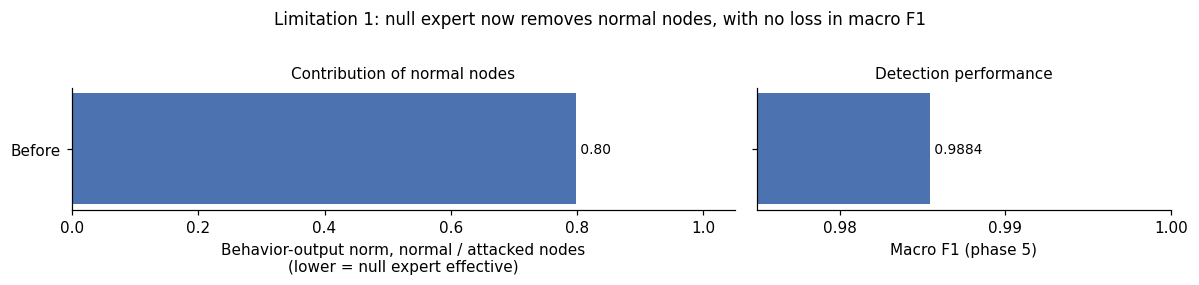

Routing to the null expert (phase 5, from the saved predictions):


,"Null routing, normal nodes","Null routing, attacked nodes"
Model,,
Two-branch (before fixes),0.760,0.041
Two-branch (final),0.711,0.043


In [15]:
from matplotlib.ticker import MaxNLocator, FormatStrFormatter
DIAG_FILES = [("Before fixes (old code)", ["old_mem_reservoir_10k", "old_bb_s42"]),
              ("Before", ["v3_fix_none_s42"]),
            #   ("v3, mask unknown IDs only", ["v3_fix_ids_s42"]),
            #   ("v3, null scaling only", ["v3_fix_null_s42"]),
              ("After", ["D_rulemax_e4_bal_s42"])]
rows = []
for lab, names in DIAG_FILES:
    for n in names:
        f = SAVE / "v3/diag" / f"{n}.json"
        if f.exists():
            d = json.load(open(f)); a = d.get("A_null", {})
            rows.append({"Model": lab, "file": n,
                         "Benign / attacked output norm": a.get("ratio_benign_over_attacked"),
                         "Real-expert weight, benign nodes": a.get("real_weight_benign"),
                         "Macro F1": d["baseline"]["macro_f1"], "Normal FPR": d["baseline"].get("normal_fpr")})
            break
null_tab = pd.DataFrame(rows).set_index("Model") if rows else pd.DataFrame()
if len(null_tab):
    display(null_tab.round(4))
    labels = list(null_tab.index)
    ratio = null_tab["Benign / attacked output norm"].astype(float).values
    f1 = null_tab["Macro F1"].astype(float).values
    col = [COLOR[NEW] if l in ("After", "Final (both fixes)", "v3, null scaling only") else COLOR[OLD]
           for l in labels]
    y = np.arange(len(labels))

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 0.9 * len(labels) + 1.6), sharey=True,
                                   gridspec_kw={"width_ratios": [1.6, 1]})
    # left: does the null expert remove normal nodes from the representation?
    bars = ax1.barh(y, ratio, color=col)
    for b, val in zip(bars, ratio):
        ax1.text(val, b.get_y() + b.get_height() / 2, f" {val:.2f}", va="center", fontsize=9)
    ax1.set_xlim(0, 1.05)
    ax1.set_yticks(y); ax1.set_yticklabels(labels)
    ax1.invert_yaxis()
    ax1.set_xlabel("Behavior-output norm, normal / attacked nodes\n(lower = null expert effective)")
    ax1.set_title("Contribution of normal nodes", fontsize=10)

    # right: macro F1 of the same models
    bars = ax2.barh(y, f1, color=col)
    for b, val in zip(bars, f1):
        ax2.text(val, b.get_y() + b.get_height() / 2, f" {val:.4f}", va="center", fontsize=9)
    lo = max(0.9, np.floor((f1.min() - 0.005) * 100) / 100)   # round down to 0.01
    ax2.set_xlim(lo, 1.0)
    ax2.xaxis.set_major_locator(MaxNLocator(nbins=3))          # at most about 3 ticks
    ax2.xaxis.set_major_formatter(FormatStrFormatter("%.2f"))
    ax2.set_xlabel("Macro F1 (phase 5)")
    ax2.set_title("Detection performance", fontsize=10)

    fig.suptitle("Limitation 1: null expert now removes normal nodes, with no loss in macro F1",
                 fontsize=11, y=1.02)
    fig.tight_layout(); savefig("fig3_null_expert"); plt.show()
else:
    print("No diagnostic files found in save/v3/diag/.")

rows = []
for lab, p in P.items():
    if has_nodes(p):
        atk = p["node_atk"] > 0
        pr = p["node_probs"].astype(np.float32)
        rows.append({"Model": lab, "Null routing, normal nodes": float(pr[~atk, 0].mean()),
                     "Null routing, attacked nodes": float(pr[atk, 0].mean())})
if rows:
    print("Routing to the null expert (phase 5, from the saved predictions):")
    display(pd.DataFrame(rows).set_index("Model").round(3))

## 4. Hạn chế 2: mở rộng thừa

**Đã sửa:** quyết định theo nhãn; với lớp mới, thử tái sử dụng expert hiện có trước, chỉ mở rộng nếu kiểm tra trên val thất bại (độ chính xác, hoặc expert hiện có không phục vụ hành vi mới: routing vào null > 0.25).

Một expert được coi là **không được dùng** nếu khối lượng routing cao nhất của nó trên mọi lớp tấn công < 0.05.

,phase2,phase3,phase4,phase5,Experts
Model,,,,,
Two-branch (before fixes),expand,ignore,expand,expand,7
Two-branch (final),expand_after_reuse,ignore,reuse,reuse,5


,Experts,Unused experts (max mass < 0.05),Max mass per expert
Model,,,
Two-branch (before fixes),7,1,E1:0.40 E2:0.94 E3:0.95 E4:0.48 E5:0.59 E6:0.0...
Two-branch (final),5,0,E1:0.55 E2:1.00 E3:0.32 E4:0.43 E5:0.74


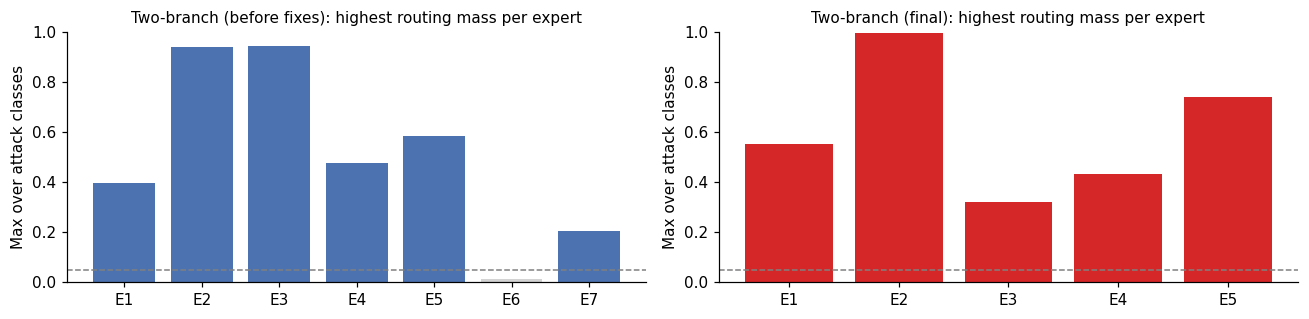

In [6]:
def expert_usage(p, min_nodes=20):
    atk, ny, pr = p["node_atk"] > 0, p["node_ny"], p["node_probs"].astype(np.float32)
    rows = [pr[atk & (ny == c)].mean(0) for c in range(1, len(CLASS_NAMES))
            if (atk & (ny == c)).sum() >= min_nodes]
    return np.vstack(rows)[:, 1:].max(0)            # real experts only

dec_rows, use_rows = [], []
for lab, r in RUNS.items():
    if not r:
        continue
    dec_rows.append({"Model": lab, **{p: r["by_phase"][p].get("decision_info", {}).get("decision", "")
                                      for p in PHASES[1:]},
                     "Experts": r["results"][-1].get("num_experts")})
    if has_nodes(P[lab]):
        mx = expert_usage(P[lab])
        use_rows.append({"Model": lab, "Experts": len(mx),
                         "Unused experts (max mass < 0.05)": int((mx < 0.05).sum()),
                         "Max mass per expert": " ".join(f"E{i+1}:{v:.2f}" for i, v in enumerate(mx))})
display(pd.DataFrame(dec_rows).set_index("Model"))
usage = pd.DataFrame(use_rows).set_index("Model") if use_rows else pd.DataFrame()
display(usage)

avail = [lab for lab in RUNS if has_nodes(P[lab])]
if avail:
    fig, axes = plt.subplots(1, len(avail), figsize=(6 * len(avail), 3), squeeze=False)
    for ax, lab in zip(axes[0], avail):
        mx = expert_usage(P[lab])
        ax.bar([f"E{i+1}" for i in range(len(mx))], mx,
               color=[COLOR[lab] if v >= 0.05 else "lightgray" for v in mx])
        ax.axhline(0.05, ls="--", color="gray", lw=1)
        ax.set_ylim(0, 1); ax.set_title(f"{lab}: highest routing mass per expert", fontsize=10)
        ax.set_ylabel("Max over attack classes")
    fig.tight_layout(); savefig("fig4_expert_usage"); plt.show()

### 4b. Mở rộng có xảy ra đúng lúc không: ba thứ tự phase

`final_*` dùng quy tắc mới; `reuse_only_*` luôn tái sử dụng, không bao giờ mở rộng (cùng phase 1). Ở `late_injection` và `late_spoof`, một kiểu hành vi vắng mặt ở phase 1 và xuất hiện ở phase 2.

,Order,Rule,Decisions P2/P3/P4/P5,Experts,Macro F1,Normal FPR,"NMI(expert, class)",Null routing of the new behavior
0,variant,Proposed rule,expand_after_reuse / ignore / reuse / reuse,5,0.9892,0.0033,0.5302,0.1031
1,variant,Always reuse,reuse / ignore / reuse / reuse,4,0.9900,0.0033,0.5020,0.4491
2,late_injection,Proposed rule,expand_after_reuse / ignore / reuse / reuse,5,0.9896,0.0034,0.5275,0.0312
3,late_injection,Always reuse,reuse / ignore / reuse / reuse,4,0.9889,0.0031,0.2441,0.6625
4,late_spoof,Proposed rule,expand_after_reuse / ignore / reuse / expand_a...,6,0.9885,0.0049,0.5275,0.0295
5,late_spoof,Always reuse,reuse / ignore / reuse / reuse,4,0.9876,0.0057,0.4622,0.3322


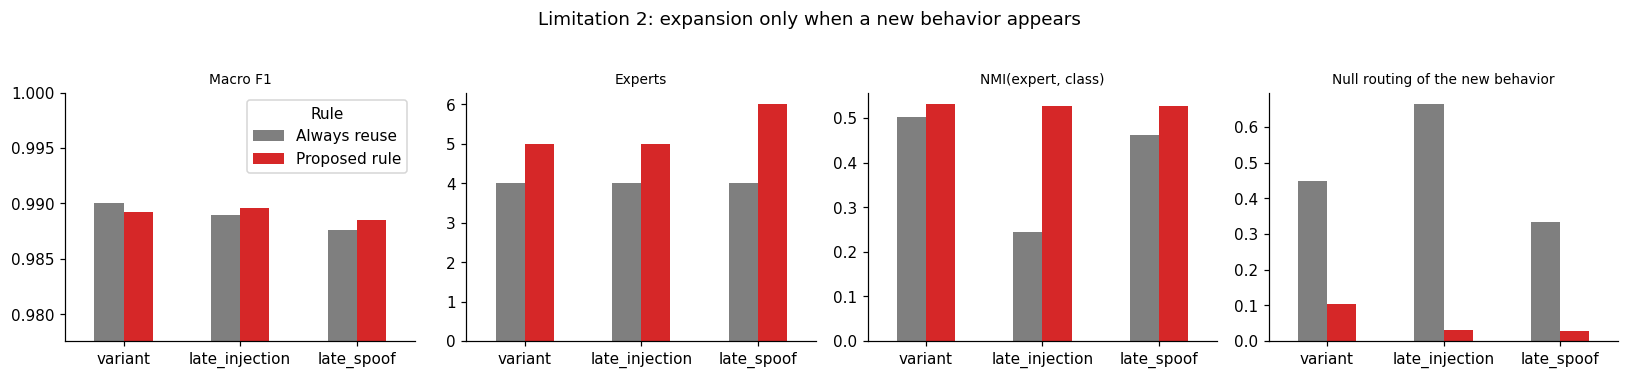

In [7]:
ORDERS = {"variant": "speed", "late_injection": "fuzzing", "late_spoof": "gear"}   # new behavior at P2
rows = []
for order, novel in ORDERS.items():
    for mode, rule in (("final", "Proposed rule"), ("reuse_only", "Always reuse")):
        r = load_run(SAVE / f"v3/impala/{mode}_{order}_s42")
        if not r:
            continue
        last = r["results"][-1]; sp = last.get("specialization") or {}
        p = load_preds(r["dir"]); nov_null = np.nan
        if has_nodes(p):
            sel = (p["node_atk"] > 0) & (p["node_ny"] == CLASS_NAMES.index(novel))
            if sel.any():
                nov_null = float(p["node_probs"][sel, 0].astype(np.float32).mean())
        rows.append({"Order": order, "Rule": rule,
                     "Decisions P2/P3/P4/P5": " / ".join(r["by_phase"][ph].get("decision_info", {}).get("decision", "")
                                                        for ph in PHASES[1:]),
                     "Experts": last.get("num_experts"), "Macro F1": last["overall"]["macro_f1"],
                     "Normal FPR": last["overall"]["normal_fpr"],
                     "NMI(expert, class)": sp.get("nmi_active_class"),
                     "Null routing of the new behavior": nov_null})
orders = pd.DataFrame(rows)
if len(orders):
    display(orders.round(4))
    fig, axes = plt.subplots(1, 4, figsize=(15, 3.3))
    for ax, k in zip(axes, ("Macro F1", "Experts", "NMI(expert, class)", "Null routing of the new behavior")):
        piv = orders.pivot(index="Order", columns="Rule", values=k).reindex([o for o in ORDERS if o in set(orders.Order)])
        piv = piv[[c for c in ("Always reuse", "Proposed rule") if c in piv]]
        piv.plot.bar(ax=ax, rot=0, legend=(k == "Macro F1"),
                     color=["#7F7F7F", COLOR[NEW]][:piv.shape[1]])
        ax.set_title(k, fontsize=9); ax.set_xlabel("")
        if k == "Macro F1":
            ax.set_ylim(max(0.95, orders[k].min() - 0.01), 1.0)
    fig.suptitle("Limitation 2: expansion only when a new behavior appears", y=1.03)
    fig.tight_layout(); savefig("fig4b_phase_orders"); plt.show()
else:
    print("No phase-order runs found in save/v3/impala/.")

## 5. Hạn chế 3: một expert trộn nhiều hành vi

**Đã sửa:** đặc trưng hành vi biểu diễn bằng mức bất ngờ conformal (cùng thang đo trên mọi tín hiệu, không phụ thuộc hướng lệch) và thêm 3 đặc trưng liên tục payload.

Hai số đo: **độ tập trung** của mỗi lớp (khối lượng routing của expert chính, không tính null) và **độ thuần** của mỗi expert (1 − entropy chuẩn hóa của phân bố lớp trên các node tấn công mà expert đó là lựa chọn hàng đầu).

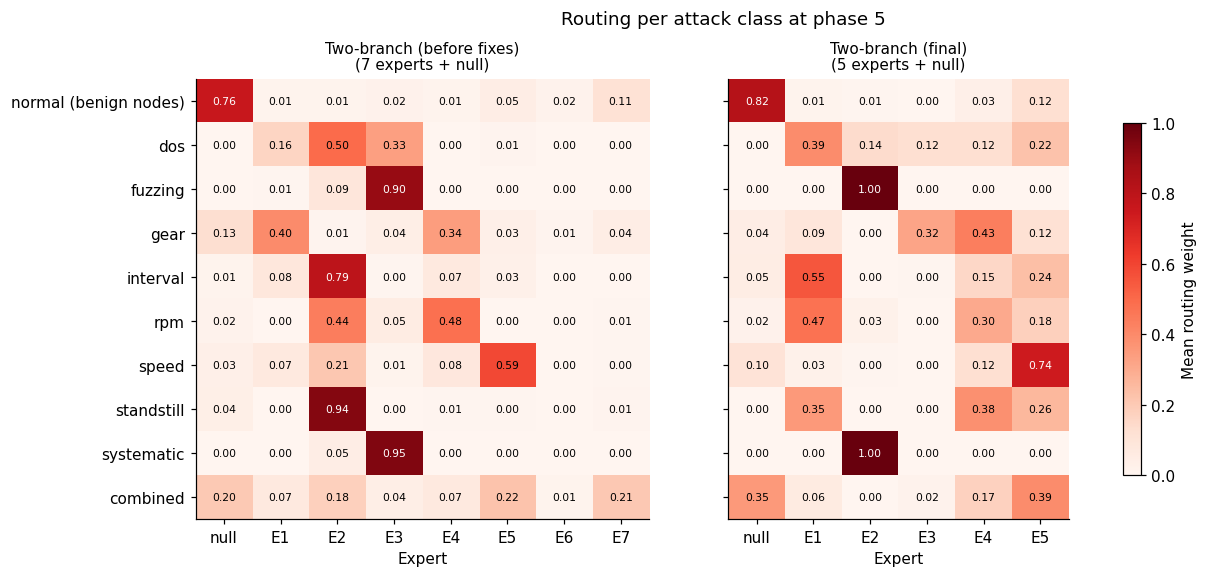

,Two-branch (before fixes),Two-branch (final)
dos,0.495,0.393
fuzzing,0.901,0.996
gear,0.396,0.434
interval,0.794,0.552
rpm,0.478,0.473
speed,0.586,0.741
standstill,0.940,0.382
systematic,0.947,0.995
combined,0.221,0.391


Expert purity (1 = the expert serves a single attack class):


,Two-branch (before fixes),Two-branch (final)
E1,0.282,0.293
E2,0.112,0.676
E3,0.606,0.542
E4,0.324,0.218
E5,0.634,0.494
E7,0.927,NaN


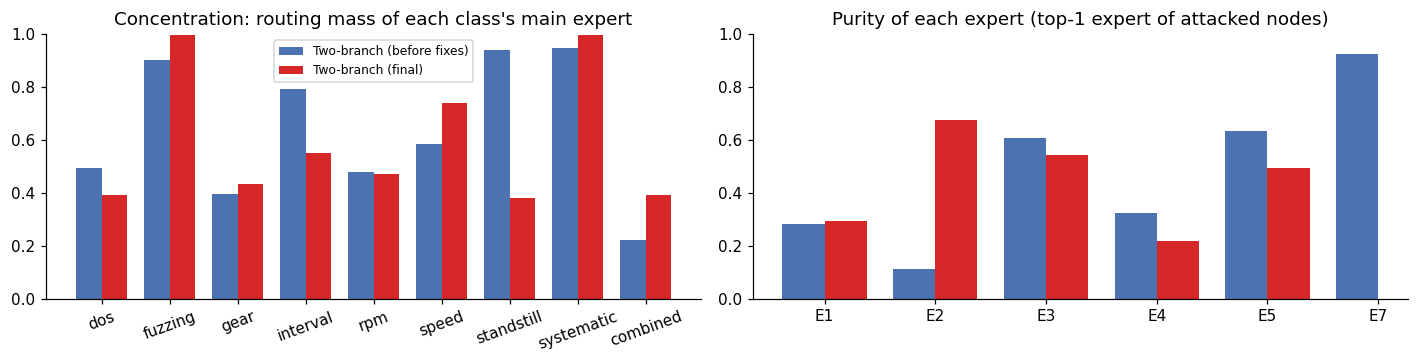

,"NMI(expert, class)","NMI(expert, CAN ID)"
Two-branch (before fixes),0.432,0.184
Two-branch (final),0.530,0.194


In [8]:
def route_matrix(p, min_nodes=20):
    atk, ny, pr = p["node_atk"] > 0, p["node_ny"], p["node_probs"].astype(np.float32)
    rows, labs = [pr[~atk].mean(0)], ["normal (benign nodes)"]
    for c in range(1, len(CLASS_NAMES)):
        sel = atk & (ny == c)
        if sel.sum() >= min_nodes:
            rows.append(pr[sel].mean(0)); labs.append(CLASS_NAMES[c])
    return np.vstack(rows), labs

avail = [lab for lab in RUNS if has_nodes(P[lab])]
if avail:
    fig, axes = plt.subplots(1, len(avail), figsize=(6.4 * len(avail), 5.2), squeeze=False,
                             gridspec_kw={"width_ratios": [P[l]["node_probs"].shape[1] for l in avail]})
    for k, (ax, lab) in enumerate(zip(axes[0], avail)):
        M, labs = route_matrix(P[lab])
        im = ax.imshow(M, vmin=0, vmax=1, cmap="Reds", aspect="auto")
        for i in range(M.shape[0]):
            for j in range(M.shape[1]):
                ax.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center", fontsize=7,
                        color="white" if M[i, j] > 0.6 else "black")
        ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(["null"] + [f"E{i}" for i in range(1, M.shape[1])])
        ax.set_yticks(range(len(labs))); ax.set_yticklabels(labs if k == 0 else [])
        ax.set_xlabel("Expert"); ax.set_title(f"{lab}\n({M.shape[1] - 1} experts + null)", fontsize=10)
    fig.colorbar(im, ax=axes[0].tolist(), shrink=0.8, label="Mean routing weight")
    fig.suptitle("Routing per attack class at phase 5", y=1.0)
    savefig("fig5_route_heatmaps"); plt.show()

conc, purity = {}, {}
for lab in avail:
    p = P[lab]
    atk, ny, pr = p["node_atk"] > 0, p["node_ny"], p["node_probs"].astype(np.float32)
    real = pr[:, 1:]
    conc[lab] = {CLASS_NAMES[c]: float(real[atk & (ny == c)].mean(0).max())
                 for c in range(1, len(CLASS_NAMES)) if (atk & (ny == c)).sum() >= 20}
    top, cls, pur = real[atk].argmax(1), ny[atk], {}
    for e in range(real.shape[1]):
        sel = top == e
        if sel.sum() >= 20:
            q = np.bincount(cls[sel], minlength=len(CLASS_NAMES))[1:].astype(float); q /= q.sum()
            pur[f"E{e+1}"] = 1 - (-(q[q > 0] * np.log(q[q > 0])).sum() / np.log(len(q)))
    purity[lab] = pur
conc, pu = pd.DataFrame(conc), pd.DataFrame(purity)
display(conc.round(3))
print("Expert purity (1 = the expert serves a single attack class):")
display(pu.round(3))

if len(conc):
    fig, axes = plt.subplots(1, 2, figsize=(13, 3.4))
    w = 0.38
    x = np.arange(len(conc))
    for i, lab in enumerate([l for l in (OLD, NEW) if l in conc]):
        axes[0].bar(x + (i - 0.5) * w, conc[lab], w, color=COLOR[lab], label=lab)
    axes[0].set_xticks(x); axes[0].set_xticklabels(conc.index, rotation=20); axes[0].set_ylim(0, 1)
    axes[0].set_title("Concentration: routing mass of each class's main expert"); axes[0].legend(fontsize=8)
    x = np.arange(len(pu))
    for i, lab in enumerate([l for l in (OLD, NEW) if l in pu]):
        axes[1].bar(x + (i - 0.5) * w, pu[lab].values, w, color=COLOR[lab], label=lab)
    axes[1].set_xticks(x); axes[1].set_xticklabels(pu.index); axes[1].set_ylim(0, 1)
    axes[1].set_title("Purity of each expert (top-1 expert of attacked nodes)")
    fig.tight_layout(); savefig("fig5b_concentration_purity"); plt.show()

nmi = pd.DataFrame({lab: {"NMI(expert, class)": (r["results"][-1].get("specialization") or {}).get("nmi_active_class"),
                          "NMI(expert, CAN ID)": (r["results"][-1].get("specialization") or {}).get("nmi_active_canid")}
                    for lab, r in RUNS.items() if r}).T
display(nmi.round(3))

## 6. Lỗi: các cặp khó (phase 5)

,Two-branch (before fixes),Two-branch (final)
fuzzing → systematic,10,15
systematic → fuzzing,14,4
combined → normal,84,96
normal → combined,80,36
speed → normal,19,12
normal → speed,27,21
standstill → rpm,1,0
rpm → standstill,1,0
false alarms (normal → any attack),116,60
missed attacks (attack → normal),159,160


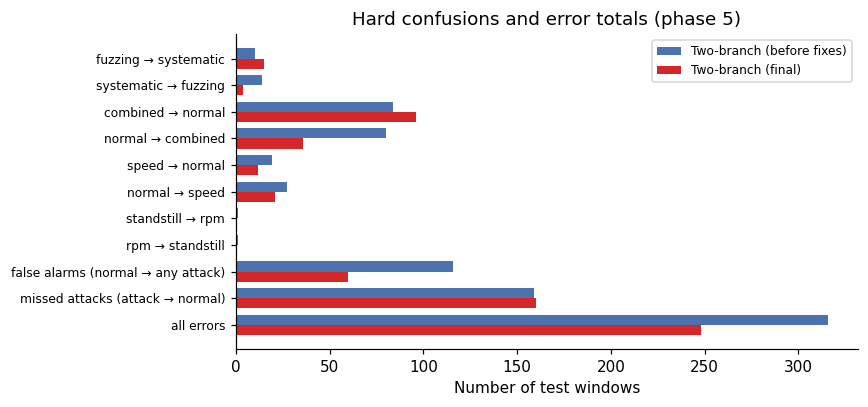

In [9]:
def confusion(p):
    y, yh = p["y"], p["logits"].astype(np.float32).argmax(1)
    K = len(CLASS_NAMES); cm = np.zeros((K, K), int); np.add.at(cm, (y, yh), 1)
    return cm

CM = {lab: confusion(p) for lab, p in P.items() if p is not None}
ix = {c: i for i, c in enumerate(CLASS_NAMES)}
pairs = [("fuzzing", "systematic"), ("systematic", "fuzzing"), ("combined", "normal"),
         ("normal", "combined"), ("speed", "normal"), ("normal", "speed"),
         ("standstill", "rpm"), ("rpm", "standstill")]
hard = pd.DataFrame({lab: [cm[ix[a], ix[b]] for a, b in pairs] for lab, cm in CM.items()},
                    index=[f"{a} → {b}" for a, b in pairs])
hard.loc["false alarms (normal → any attack)"] = {lab: int(cm[0, 1:].sum()) for lab, cm in CM.items()}
hard.loc["missed attacks (attack → normal)"] = {lab: int(cm[1:, 0].sum()) for lab, cm in CM.items()}
hard.loc["all errors"] = {lab: int(cm.sum() - np.trace(cm)) for lab, cm in CM.items()}
display(hard)
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(hard)); h = 0.38
for i, lab in enumerate([l for l in (OLD, NEW) if l in hard]):
    ax.barh(y + (i - 0.5) * h, hard[lab], h, color=COLOR[lab], label=lab)
ax.set_yticks(y); ax.set_yticklabels(hard.index, fontsize=8); ax.invert_yaxis()
ax.set_xlabel("Number of test windows"); ax.set_title("Hard confusions and error totals (phase 5)")
ax.legend(fontsize=8); fig.tight_layout(); savefig("fig6_hard_pairs"); plt.show()

## 7. Tổng hợp các điểm đã sửa

In [10]:
def get(df, row, col):
    try:
        v = df.loc[row, col]
        return None if (v is None or (isinstance(v, float) and np.isnan(v))) else v
    except (KeyError, TypeError):
        return None

def fmt(v, d=3):
    if v is None:
        return "n/a"
    return f"{v:.{d}f}" if isinstance(v, (float, np.floating)) and d > 0 else f"{int(v)}" if d == 0 else str(v)

fixes = pd.DataFrame([
    {"Limitation": "1. Null expert only in routing",
     "Fix": "Scale the behavior output by the real-expert weight",
     "Evidence (before → final)":
        f"normal/attacked output norm {fmt(get(null_tab, 'Before fixes (old code)', 'Benign / attacked output norm'), 2)}"
        f" → {fmt(get(null_tab, 'Final (both fixes)', 'Benign / attacked output norm'), 2)}"},
    {"Limitation": "2. Unnecessary expansion",
     "Fix": "Label-gated decision, verified reuse, routing check",
     "Evidence (before → final)":
        f"experts {fmt(get(summary, OLD, 'Experts'), 0)} → {fmt(get(summary, NEW, 'Experts'), 0)}; "
        f"unused {fmt(get(usage, OLD, 'Unused experts (max mass < 0.05)'), 0)} → "
        f"{fmt(get(usage, NEW, 'Unused experts (max mass < 0.05)'), 0)}"},
    {"Limitation": "3. Mixed behaviors in one expert",
     "Fix": "Conformal surprise + payload-continuity features",
     "Evidence (before → final)":
        f"NMI(expert, class) {fmt(get(nmi, OLD, 'NMI(expert, class)'))} → {fmt(get(nmi, NEW, 'NMI(expert, class)'))}"},
    {"Limitation": "Protocol",
     "Fix": "Normal profiles from phase-1 recordings only; reuse check on one validation set",
     "Evidence (before → final)":
        f"macro F1 {fmt(get(summary, OLD, 'Macro F1'), 4)} → {fmt(get(summary, NEW, 'Macro F1'), 4)}, "
        f"FPR {fmt(get(summary, OLD, 'Normal FPR'), 4)} → {fmt(get(summary, NEW, 'Normal FPR'), 4)}"},
])
pd.set_option("display.max_colwidth", 140)
display(fixes)
summary.to_csv(FIG / "summary.csv"); pc.to_csv(FIG / "per_class_f1.csv"); fixes.to_csv(FIG / "fixes.csv", index=False)
if len(orders):
    orders.to_csv(FIG / "phase_orders.csv", index=False)
print("Saved to", FIG.resolve())

,Limitation,Fix,Evidence (before → final)
0,1. Null expert only in routing,Scale the behavior output by the real-expert weight,normal/attacked output norm n/a → 0.16
1,2. Unnecessary expansion,"Label-gated decision, verified reuse, routing check",experts 7 → 5; unused 1 → 0
2,3. Mixed behaviors in one expert,Conformal surprise + payload-continuity features,"NMI(expert, class) 0.432 → 0.530"
3,Protocol,Normal profiles from phase-1 recordings only; reuse check on one validation set,"macro F1 0.9861 → 0.9892, FPR 0.0064 → 0.0033"


Saved to /home/hieutt/MoE-IVN-IDS/notebooks/figures/before_after
